<a href="https://colab.research.google.com/github/RajatSharma-2007/HCL_PROJECT/blob/main/Project_HCL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 1) Calculate average first-period, second-period, and final grades.
import numpy as np
import pandas as pd

students = pd.read_csv("student-mat.csv", sep=";")

# Convert each grade column into a NumPy array, then calculate its mean.
g1 = students["G1"].to_numpy(dtype=float)
g2 = students["G2"].to_numpy(dtype=float)
g3 = students["G3"].to_numpy(dtype=float)

avg1 = np.mean(g1)
avg2 = np.mean(g2)
avg3 = np.mean(g3)

print("Average grades out of 20:")
print(f"First-period grade (G1):  {avg1:.2f}")  #.2f is used to get only 2 digits after decimal
print(f"Second-period grade (G2): {avg2:.2f}")
print(f"Final grade (G3):         {avg3:.2f}")


Average grades out of 20:
First-period grade (G1):  10.91
Second-period grade (G2): 10.71
Final grade (G3):         10.42


In [11]:
# 2) Count students in four final-grade bands.
import pandas as pd

students = pd.read_csv("student-mat.csv", sep=";")

# Divide final grades into simple ranges.
bands = pd.cut(                                    #pd.cut converts into ranges
    students["G3"],
    bins=[-1, 4, 9, 14, 20],
    labels=["0-4", "5-9", "10-14", "15-20"],
)
band_counts = bands.value_counts(sort=False)
print("Number of students in each final-grade band:")
print(band_counts)

Number of students in each final-grade band:
G3
0-4       39
5-9       91
10-14    192
15-20     73
Name: count, dtype: int64


In [12]:
# 3) Compare average final grade by gender.
import pandas as pd

students = pd.read_csv("student-mat.csv", sep=";")
print("Average final grade (G3) by gender:")
print(students.groupby("sex")["G3"].mean().round(2))
print("\nThis is a descriptive comparison; it does not show cause and effect.")


Average final grade (G3) by gender:
sex
F     9.97
M    10.91
Name: G3, dtype: float64

This is a descriptive comparison; it does not show cause and effect.


In [13]:
# 4) Compare grades by study time.
import pandas as pd

students = pd.read_csv("student-mat.csv", sep=";")
labels = {1: "<2 hours", 2: "2-5 hours", 3: "5-10 hours", 4: ">10 hours"}
students["study_time_category"] = students["studytime"].map(labels)
print("Average final grade and student count by weekly study time:")
print(students.groupby("study_time_category")["G3"].agg(["mean", "count"]).round(2))

Average final grade and student count by weekly study time:
                      mean  count
study_time_category              
2-5 hours            10.17    198
5-10 hours           11.40     65
<2 hours             10.05    105
>10 hours            11.26     27


In [14]:
# 5) Find the student record(s) with the most absences.
import pandas as pd

students = pd.read_csv("student-mat.csv", sep=";")
highest_absences = students["absences"].max()
most_absent = students.loc[students["absences"] == highest_absences,
                           ["sex", "age", "studytime", "absences", "G3"]]
print("Highest absence count:", highest_absences)
print("Record(s) with the highest absences (sex, age, studytime, absences, G3):")
print(most_absent.to_string(index=False))
print("\nThe dataset has no student names or IDs, so these are shown as records.")


Highest absence count: 75
Record(s) with the highest absences (sex, age, studytime, absences, G3):
sex  age  studytime  absences  G3
  F   18          2        75   9

The dataset has no student names or IDs, so these are shown as records.


In [15]:
# 6) Check the dataset for missing values and duplicate rows."""
import pandas as pd

students = pd.read_csv("student-mat.csv", sep=";")

missing_by_column = students.isna().sum()
print("Missing values in each column:")
print(missing_by_column)
print("\nTotal missing values:", missing_by_column.sum())
print("Duplicate rows:", students.duplicated().sum())


Missing values in each column:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

Total missing values: 0
Duplicate rows: 0


Histogram saved as grade_histogram.png


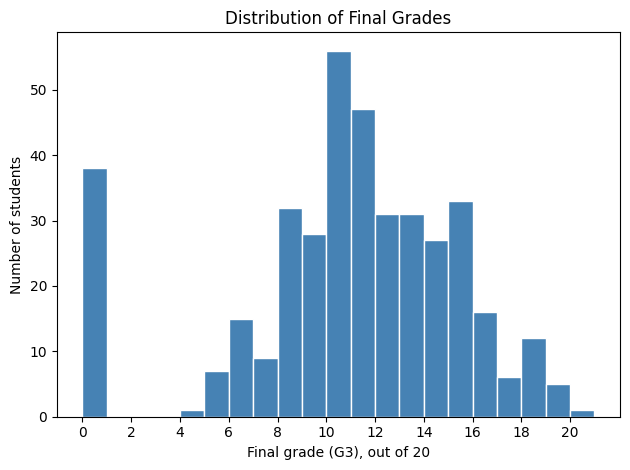

In [ ]:
# Histogram showing the distribution of final grades (G3).
import matplotlib.pyplot as plt
import pandas as pd

students = pd.read_csv("student-mat.csv", sep=";")

plt.hist(students["G3"], bins=range(0, 22), color="steelblue", edgecolor="white")
plt.title("Distribution of Final Grades")
plt.xlabel("Final grade (G3), out of 20")
plt.ylabel("Number of students")
plt.xticks(range(0, 21, 2))
plt.tight_layout()
plt.savefig("grade_histogram.png", dpi=160)
print("Histogram saved as grade_histogram.png")

Chart saved as study_time_count.png


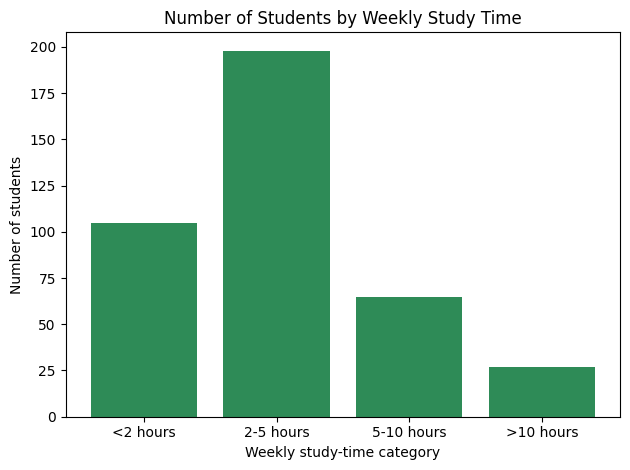

In [16]:
# Bar chart showing the number of students per study-time group.
import matplotlib.pyplot as plt
import pandas as pd

students = pd.read_csv("student-mat.csv", sep=";")

study_time_names = {
    1: "<2 hours",
    2: "2-5 hours",
    3: "5-10 hours",
    4: ">10 hours",
}
students["study_time_category"] = students["studytime"].map(study_time_names)
student_counts = students["study_time_category"].value_counts().reindex(
    [study_time_names[number] for number in range(1, 5)], fill_value=0
)

plt.bar(student_counts.index, student_counts.values, color="seagreen")
plt.title("Number of Students by Weekly Study Time")
plt.xlabel("Weekly study-time category")
plt.ylabel("Number of students")
plt.tight_layout()
plt.savefig("study_time_count.png", dpi=160)
print("Chart saved as study_time_count.png")


In [17]:
# Observations:


# Calculate the most common range and counts from the existing band_counts
# bands was calculated in cell KHtwUvwTVYFX
bands = pd.cut(
    students["G3"],
    bins=[-1, 4, 9, 14, 20],
    labels=["0-4", "5-9", "10-14", "15-20"],
)
range_counts = bands.value_counts(sort=False)
most_common_range = range_counts.idxmax()

# Map study time categories to calculate study_averages and highest_study_group
study_time_names = {
    1: "<2 hours",
    2: "2-5 hours",
    3: "5-10 hours",
    4: ">10 hours",
}
students["study_time_category"] = students["studytime"].map(study_time_names)
study_averages = students.groupby("study_time_category")["G3"].mean()
highest_study_group = study_averages.idxmax()

print(f"Observation 1: The average grade decreases from {avg1:.2f} in G1 "
    f"to {avg2:.2f} in G2 and {avg3:.2f} in G3.")
print(f"Observation 2: The {most_common_range} final-grade range is the most "
    f"common, with {range_counts[most_common_range]} students.")
print(f"Observation 3: The {highest_study_group} study-time group has the "
    f"highest average final grade, {study_averages[highest_study_group]:.2f}.")

Observation 1: The average grade decreases from 10.91 in G1 to 10.71 in G2 and 10.42 in G3.
Observation 2: The 10-14 final-grade range is the most common, with 192 students.
Observation 3: The 5-10 hours study-time group has the highest average final grade, 11.40.
